House Price Prediction using Linear Regression
Project documentation outline

1. Introduction
This project demonstrates a basic machine-learning workflow for predicting house prices using Linear Regression.
2. Objective
Predict an illustrative house price from its size and number of bedrooms.
3. Dataset
A small, manually created dataset containing 20 examples, two input features and one target variable. The prices are illustrative rather than actual market observations.
4. Methodology
- Data creation and exploration
- Feature and target separation
- Train/test split
- Linear Regression training
- Prediction and evaluation
5. Evaluation
Report your actual MAE, RMSE and \(R^2\) results from the notebook. Don't invent or manually alter the scores.
6. Limitations
The dataset is tiny and artificial. It excludes location, property condition, age, local market trends and many other factors. The results should not be used to price real homes.
7. Conclusion
# The project demonstrates the end-to-end process of training, evaluating, using and saving a simple regression model.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("All libraries imported succ3essfully")

data = {
    "size_sqft": [500, 700, 900, 1100, 1300,
                  1500, 1700, 1900, 2100, 2300,
                  2500, 2700, 2900, 3100, 3300,
                  3500, 3700, 3900, 4100, 4300],

    "bedrooms": [1, 1, 2, 2, 3,
                 3, 3, 4, 4, 4,
                 4, 5, 5, 5, 5,
                 6, 6, 6, 7, 7],

    "price_lakhs": [20, 25, 30, 35, 40,
                    45, 48, 53, 57, 60,
                    65, 70, 74, 78, 83,
                    88, 92, 96, 102, 108]
}

df=pd.DataFrame(data)
df.head()

All libraries imported succ3essfully


,size_sqft,bedrooms,price_lakhs
0,500,1,20
1,700,1,25
2,900,2,30
3,1100,2,35
4,1300,3,40


In [2]:
print(df.shape)
print(df.columns)
df.info()
print(df.describe())
print(df.isnull().sum())


(20, 3)
Index(['size_sqft', 'bedrooms', 'price_lakhs'], dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   size_sqft    20 non-null     int64
 1   bedrooms     20 non-null     int64
 2   price_lakhs  20 non-null     int64
dtypes: int64(3)
memory usage: 612.0 bytes
         size_sqft   bedrooms  price_lakhs
count    20.000000  20.000000    20.000000
mean   2400.000000   4.150000    63.450000
std    1183.215957   1.814416    26.442539
min     500.000000   1.000000    20.000000
25%    1450.000000   3.000000    43.750000
50%    2400.000000   4.000000    62.500000
75%    3350.000000   5.250000    84.250000
max    4300.000000   7.000000   108.000000
size_sqft      0
bedrooms       0
price_lakhs    0
dtype: int64


In [3]:
X=df[["size_sqft", "bedrooms"]]
y=df["price_lakhs"]
print("Feature shape:",X.shape)
print("Target shape:", y.shape)

Feature shape: (20, 2)
Target shape: (20,)


In [5]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [6]:
y_pred =model.predict(X_test)
results=pd.DataFrame({"Actual": y_test.values, "Predicted": y_pred.round(2)})
print(results)

   Actual  Predicted
0      20      20.66
1      96      96.46
2      88      88.36
3      25      24.71


In [7]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 0.4411135522664251
MSE: 0.21364079477344658
RMSE: 0.46221293228710786
R2 Score: 0.9998246959989551


In [8]:
print("Intercept:", round(model.intercept_, 3))

for feature, coefficient in zip(X.columns, model.coef_):
    print(f"{feature}: {coefficient:.4f}")

Intercept: 9.142
size_sqft: 0.0203
bedrooms: 1.3794


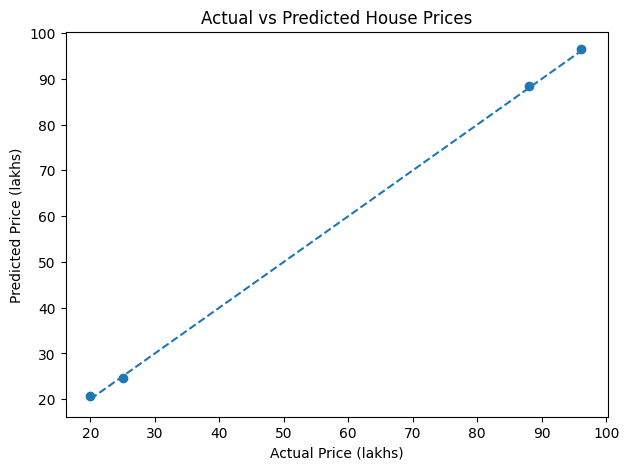

In [9]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred)

lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())

plt.plot([lower, upper], [lower, upper], linestyle="--")

plt.xlabel("Actual Price (lakhs)")
plt.ylabel("Predicted Price (lakhs)")
plt.title("Actual vs Predicted House Prices")

plt.show()

In [10]:
new_house = pd.DataFrame({
    "size_sqft": [2000],
    "bedrooms": [3]
})

predicted_price = model.predict(new_house)

print(f"Predicted house price: ₹{predicted_price[0]:.2f} lakhs")

Predicted house price: ₹53.82 lakhs


In [11]:
error_results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred,
    "Error": y_test.values - y_pred
})

error_results["Absolute Error"] = error_results["Error"].abs()

print(error_results.round(2))

   Actual Price  Predicted Price  Error  Absolute Error
0            20            20.66  -0.66            0.66
1            96            96.46  -0.46            0.46
2            88            88.36  -0.36            0.36
3            25            24.71   0.29            0.29


In [12]:
import joblib

joblib.dump(model, "house_price_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [13]:
from google.colab import files

files.download("house_price_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>